# 04 · Cross-market transfer, fairness audit and deployment
**ProSit 2 · ICS553** · Part C (Kenya → Ghana transfer), Part D (ethical and regulatory audit), Part E (scoring service).

Requires `outputs/artifacts/classification.joblib` (notebook 02) and `outputs/artifacts/regression.joblib` (notebook 03).

### Running in Google Colab
Run the next cell first (it does nothing when you run locally). It mounts Google Drive, clones this repo into the Colab VM,
installs the libraries Colab lacks, reads the data from `DRIVE_DIR/data` and writes all outputs to `DRIVE_DIR/outputs`.
Outputs must live on Drive because **each Colab notebook runs on its own VM**: notebook 04 needs the files that 02 and 03
save, and checkpoints on Drive let an interrupted run resume. Put `Train.csv`, `Test.csv`, `economic_indicators.csv` and
`micro_gha.csv` in `DRIVE_DIR/data` once; every teammate uses the same layout.

In [1]:
# ---- Google Colab setup (skipped automatically when running locally) ----
import os, sys, subprocess
from pathlib import Path
if 'google.colab' in sys.modules:
    REPO_URL = 'https://github.com/isanamoa/MLE-PROSIT-2.git'
    BRANCH = 'main'                                   # change if the team works on another branch
    DRIVE_DIR = '/content/drive/MyDrive/MLE Prosit 2'  # your Drive folder; data in DRIVE_DIR/data
    from google.colab import drive
    drive.mount('/content/drive')
    repo = Path('/content/MLE-PROSIT-2')
    if not (repo / 'src' / 'prosit2').exists():
        subprocess.run(['git', 'clone', '--depth', '1', '-b', BRANCH, REPO_URL, str(repo)], check=True)
    else:
        subprocess.run(['git', '-C', str(repo), 'pull', '--ff-only'], check=False)
    os.chdir(repo)
    # Colab already has numpy/pandas/scipy/scikit-learn/matplotlib; install only what is missing (no version pins,
    # so no runtime restart is needed). Tested versions are listed in requirements.txt.
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'imbalanced-learn', 'lightgbm', 'xgboost', 'shap', 'fairlearn'], check=True)
    data_dir = Path(DRIVE_DIR) / 'data'
    os.environ['PROSIT2_DATA_DIR'] = str(data_dir if (data_dir / 'Train.csv').exists() else repo / 'data')
    os.environ['PROSIT2_OUT_DIR'] = str(Path(DRIVE_DIR) / 'outputs')   # FAST mode writes to outputs_fast automatically
    assert (Path(os.environ['PROSIT2_DATA_DIR']) / 'Train.csv').exists(), f'Put Train.csv etc. in {data_dir}'
    print('Colab ready | data:', os.environ['PROSIT2_DATA_DIR'], '| outputs:', os.environ['PROSIT2_OUT_DIR'])
else:
    print('Not running in Colab: nothing to do.')

Not running in Colab: nothing to do.


In [2]:
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'prosit2').exists())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from prosit2.config import CFG, apply_fast_mode, output_dirs, write_environment, savefig, seed_everything, money, F

# CFG.update(FAST=True)        # <- uncomment for a quick smoke test (or set env PROSIT2_FAST=1)
apply_fast_mode(CFG)
SEED = CFG['SEED']; seed_everything(SEED)
DIRS = output_dirs(CFG)
FX, CUR = money(CFG)           # report amounts in GHS only once CFG['FX_TO_GHS'] is set
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
print(f'Repo root: {ROOT}\nOutputs:   {CFG["OUT_DIR"]}\nFAST mode: {CFG["FAST"]} | currency for reporting: {CUR}')

Repo root: <repo>
Outputs:   <repo>\outputs
FAST mode: False | currency for reporting: KES


In [3]:
import json, joblib
from scipy import stats
from scipy.special import expit, logit
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, f1_score
from imblearn.pipeline import Pipeline as ImbPipeline
import lightgbm as lgb
from prosit2.data import prepare_dataset, clean_unlabelled, make_features, load_findex, size_band
from prosit2.models import make_preprocessor, get_score
from prosit2.evaluation import cost_vectors, expected_cost, topq_threshold, ci95, psi
from prosit2.features import CAT_COLS
from prosit2.explain import contributions, ReasonBuilder, REASONS, source_col
ENV = write_environment(DIRS, CFG, 'environment_04.json')

for f in ('classification.joblib', 'regression.joblib'):
    assert (DIRS['artifacts'] / f).exists(), f'Run notebooks 02 and 03 first (missing {f})'
A = joblib.load(DIRS['artifacts'] / 'classification.joblib'); R = joblib.load(DIRS['artifacts'] / 'regression.joblib')
ds = prepare_dataset(CFG)
dev, test, lab = ds.dev, ds.test, ds.lab
y_dev, y_te = ds.y_dev, test['target'].values
FINAL_FEATS, FINAL_MODEL, FINAL_EXP = A['FINAL_FEATS'], A['FINAL_MODEL'], A['FINAL_EXP']
pipe_f, cal_f, thr_f = A['final']['pipe'], A['final']['cal'], A['final']['thr']
p_te, oofp = A['p_test_final'], A['oof_final_cal_full']
assert np.allclose(cal_f.predict(get_score(pipe_f, test)), p_te), 'artifacts do not match the current data/split: re-run 02'
fn_te, fp_te = cost_vectors(test, cfg=CFG)
print(f'Final model {FINAL_MODEL} ({FINAL_EXP}) | threshold {thr_f:.4f} | test PR-AUC {A["TEST"]["final"]["pr_auc"]:.4f}')

Train (68654, 16) -> cleaned 68,654 loans (default rate 1.832%)
Test starts 2022-11-02 | dev 52,331 (defaults 674, 1.29%) | test 13,775 (defaults 533, 3.87%) | purged 2,548
Feature groups: {'base': 4, 'calendar': 7, 'terms': 7, 'history': 8, 'macro': 7} | model features: Task 2 = 26, Task 1 = 19 (macro as model input: False)
Final model lgbm (S3_lgbm_tuned) | threshold 0.1923 | test PR-AUC 0.6109


## 1. Cross-market transfer: Kenya → Ghana (Part C)
Ghana has **no labels**, so performance cannot be measured; we can only measure *how different* Ghanaian applications are
and what the Kenyan model does to them: feature-distribution comparison (PSI, KS), a **domain classifier**, **importance
weights** from it, and the score distribution on both markets. Test.csv rows are featurised with history from Train only.

In [4]:
tst = clean_unlabelled(ds.test_raw)
tst_f = make_features(tst, lab, ds.econ, CFG)
cn = tst_f['country_id'].astype(str)
GHANA = 'Ghana'; assert (cn == GHANA).sum() > 50, 'Ghana rows not found in Test.csv'
tst_f['market'] = np.where(cn == GHANA, 'Ghana', 'Kenya')
print(tst_f['market'].value_counts().to_dict())
G, K_te = tst_f[tst_f.market == 'Ghana'], tst_f[tst_f.market == 'Kenya']
STATIC = [c for c in ds.groups['base'] + ds.groups['terms'] + ds.groups['calendar'] if c != 'amount_vs_prior_mean']
rows = []
for c in STATIC + ds.groups['macro']:
    isc = c in CAT_COLS; r_ = {'feature': c, 'PSI (Kenya dev -> Ghana)': psi(dev[c], G[c], cat=isc)}
    if not isc: r_['KS stat'] = stats.ks_2samp(dev[c].dropna(), G[c].dropna()).statistic if G[c].notna().any() else np.nan
    rows.append(r_)
shift = pd.DataFrame(rows).sort_values('PSI (Kenya dev -> Ghana)', ascending=False)
shift['reading'] = pd.cut(shift['PSI (Kenya dev -> Ghana)'], [-1, .1, .25, 1e9], labels=['stable', 'moderate shift', 'major shift'])
display(shift.round(3)); shift.to_csv(DIRS['results'] / 'transfer_feature_shift.csv', index=False)
for c in ['lender_id', 'loan_type']:
    print(f'Share of Ghana rows whose {c} also exists in Kenyan training data: {100*G[c].isin(set(dev[c])).mean():.1f}%')
print('Ghana customers with any prior loan in Train history: %.1f%% (Kenya Test.csv: %.1f%%)' % (100 * (G.n_prior_loans > 0).mean(), 100 * (K_te.n_prior_loans > 0).mean()))
if ds.groups['macro']:
    print('\nMacro context by market (Ghana values lie far outside the Kenyan training range, so tree models treat them as the nearest Kenyan value):')
    display(pd.concat({'Kenya dev': dev[ds.groups['macro']].describe().loc[['min', 'max']], 'Ghana': G[ds.groups['macro']].describe().loc[['min', 'max']]}).T.round(2))

{'Kenya': 15069, 'Ghana': 3525}


,feature,PSI (Kenya dev -> Ghana),KS stat,reading
1,loan_type,17.657,NaN,major shift
2,lender_id,17.032,NaN,major shift
22,macro_real_interest_rate,9.210,NaN,major shift
20,macro_lending_interest_rate,9.210,NaN,major shift
19,macro_interest_rate_spread_lending_rate_minus_...,9.210,NaN,major shift
8,lender_repay_share,5.786,0.644,major shift
5,fee_rate,5.437,0.776,major shift
7,lender_funded_share,4.744,0.654,major shift
9,Lender_portion_Funded,4.732,0.654,major shift
6,daily_fee_rate,4.409,0.674,major shift


Share of Ghana rows whose lender_id also exists in Kenyan training data: 3.3%
Share of Ghana rows whose loan_type also exists in Kenyan training data: 12.7%
Ghana customers with any prior loan in Train history: 0.0% (Kenya Test.csv: 89.6%)

Macro context by market (Ghana values lie far outside the Kenyan training range, so tree models treat them as the nearest Kenyan value):


Kenya dev          Ghana  \
                                                         min     max    min   
macro_deposit_interest_rate                             6.69    6.97  11.50   
macro_inflation_consumer_prices_annual                  5.41    6.11   9.89   
macro_interest_rate_spread_lending_rate_minus_d...      5.03    5.39    NaN   
macro_lending_interest_rate                            12.00   12.08    NaN   
macro_official_exchange_rate_lcu_per_us_period_...    106.45  109.64   5.60   
macro_real_interest_rate                                6.71    7.43    NaN   
macro_unemployment_rate                                 5.62    5.69   3.08   

                                                           
                                                      max  
macro_deposit_interest_rate                         12.05  
macro_inflation_consumer_prices_annual              31.26  
macro_interest_rate_spread_lending_rate_minus_d...    NaN  
macro_lending_interest_rate                           NaN  
macro_official_exchange_rate_lcu_per_us_period_...   8.27  
macro_real_interest_rate                              NaN  
macro_unemployment_rate                              3.34

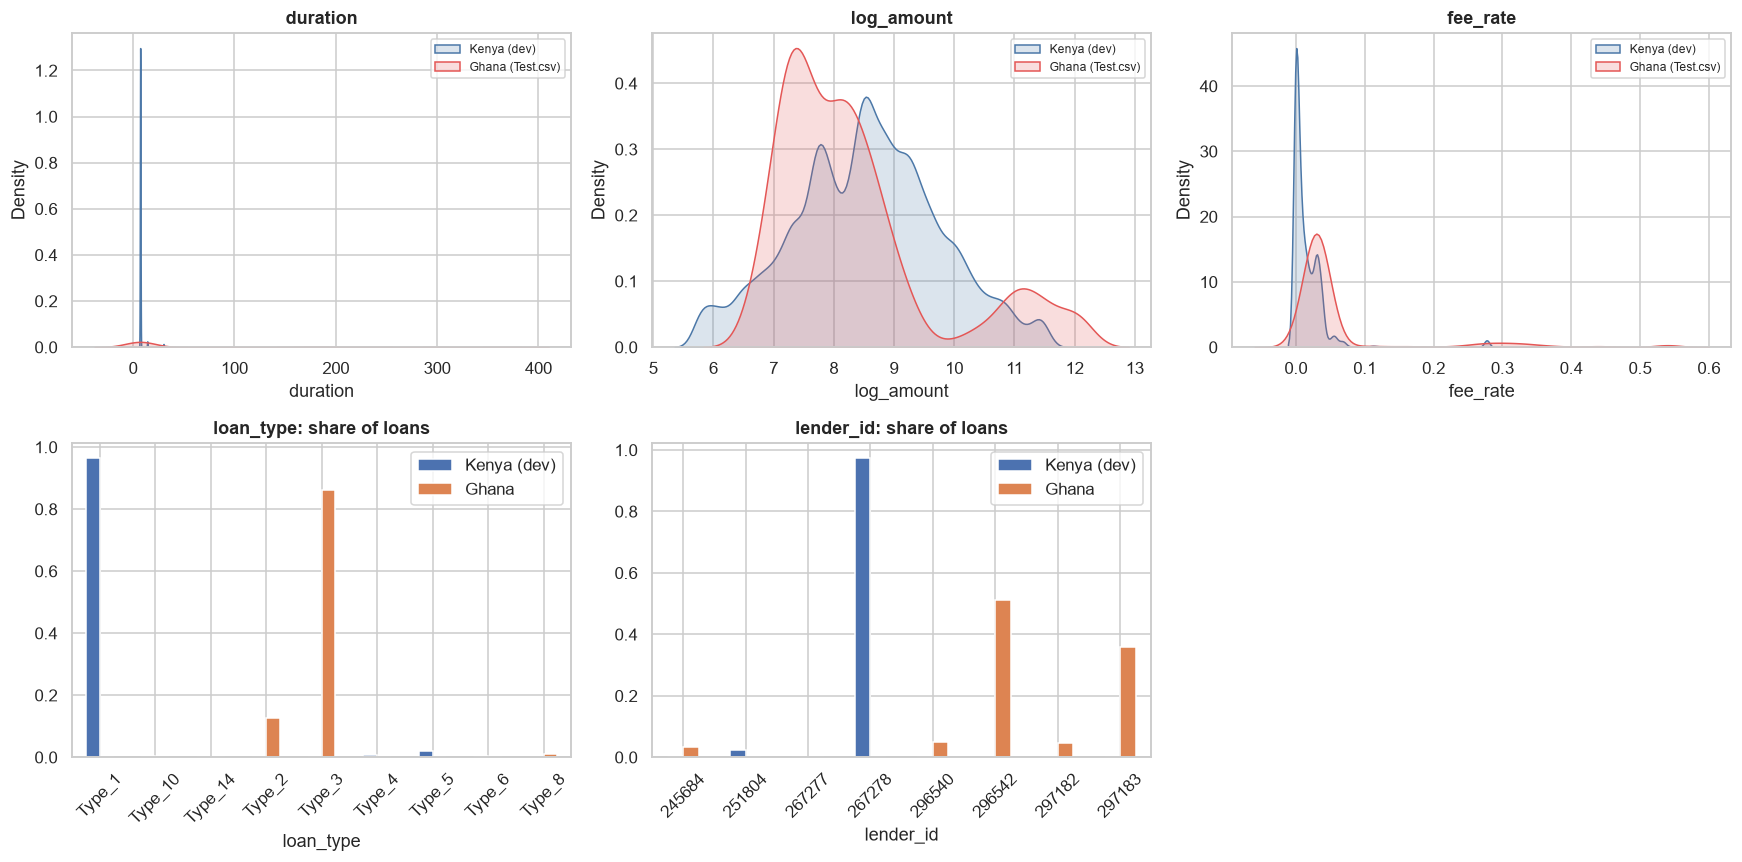

Domain classifier ROC-AUC (Kenya vs Ghana, cross-validated) = 1.000  (0.5 = indistinguishable, 1.0 = fully separable)


Features that most distinguish Ghana from Kenya (gain share):
 lender_id                0.683
loan_type                0.262
duration                 0.046
Lender_portion_Funded    0.007
lender_funded_share      0.001
fee_rate                 0.001


Domain AUC without lender_id/loan_type: 1.000
Importance weights: effective sample size 52,331 of 52,331 (100.0%)
Dev OOF PR-AUC unweighted 0.9694 | Ghana-reweighted 0.9694 ; default rate unweighted 0.0129 | reweighted 0.0129
Reweighted numbers are Kenyan evidence about Ghana-LIKE Kenyan loans, not Ghanaian outcomes; with near-perfect separability they say little.


In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(ax.ravel()[:3], ['duration', 'log_amount', 'fee_rate']):
    for d_, nm, col in [(dev, 'Kenya (dev)', '#4C78A8'), (G, 'Ghana (Test.csv)', '#E45756')]:
        sns.kdeplot(d_[c].dropna().clip(d_[c].quantile(.01), d_[c].quantile(.99)), ax=a, label=nm, color=col, fill=True, alpha=.2, common_norm=False)
    a.set_title(c); a.legend(fontsize=8)
for a, c in zip(ax.ravel()[3:5], ['loan_type', 'lender_id']):
    top = pd.Index(dev[c].value_counts().head(6).index).union(G[c].value_counts().head(4).index)
    pd.DataFrame({'Kenya (dev)': dev[c].value_counts(normalize=True).reindex(top), 'Ghana': G[c].value_counts(normalize=True).reindex(top)}).fillna(0).plot.bar(ax=a)
    a.set_title(f'{c}: share of loans'); a.tick_params(axis='x', rotation=45)
ax.ravel()[5].axis('off'); plt.tight_layout(); savefig(fig, DIRS, 'plots_tr', 'transfer_feature_distributions')

# Domain classifier: can we tell Kenya (dev) from Ghana?
dom = pd.concat([dev[STATIC].assign(_d=0), G[STATIC].assign(_d=1)], ignore_index=True); yd = dom.pop('_d')
dpipe = ImbPipeline([('prep', make_preprocessor(STATIC)), ('clf', lgb.LGBMClassifier(n_estimators=F(150, 40), learning_rate=0.05, num_leaves=15, min_child_samples=30, random_state=SEED, n_jobs=-1, verbose=-1))])
pd_oof = cross_val_predict(dpipe, dom, yd, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
DOMAIN_AUC = roc_auc_score(yd, pd_oof)
print(f'Domain classifier ROC-AUC (Kenya vs Ghana, cross-validated) = {DOMAIN_AUC:.3f}  (0.5 = indistinguishable, 1.0 = fully separable)')
dpipe.fit(dom, yd); dprep, dclf = dpipe.named_steps['prep'], dpipe.named_steps['clf']
dimp = pd.Series(dclf.booster_.feature_importance('gain'), index=dprep.get_feature_names_out()).groupby(lambda n: source_col(n, STATIC)).sum().sort_values(ascending=False)
print('Features that most distinguish Ghana from Kenya (gain share):\n', (dimp / dimp.sum()).head(6).round(3).to_string())

# Domain classifier WITHOUT lender/loan_type: is there shift beyond the product catalogue?
STATIC_NP = [c for c in STATIC if c not in ('lender_id', 'loan_type')]
dom2 = pd.concat([dev[STATIC_NP].assign(_d=0), G[STATIC_NP].assign(_d=1)], ignore_index=True); yd2 = dom2.pop('_d')
dp2 = ImbPipeline([('prep', make_preprocessor(STATIC_NP)), ('clf', lgb.LGBMClassifier(n_estimators=F(150, 40), learning_rate=0.05, num_leaves=15, min_child_samples=30, random_state=SEED, n_jobs=-1, verbose=-1))])
print('Domain AUC without lender_id/loan_type: %.3f' % roc_auc_score(yd2, cross_val_predict(dp2, dom2, yd2, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]))

# Importance weights for Kenyan dev rows: w = p/(1-p) * nK/nG, clipped at the 99th percentile, mean-normalised
pk = np.clip(pd_oof[:len(dev)], 1e-4, 1 - 1e-4); w = pk / (1 - pk) * (len(dev) / len(G)); w = np.minimum(w, np.quantile(w, .99)); w = w / w.mean()
ess = w.sum() ** 2 / (w ** 2).sum(); print(f'Importance weights: effective sample size {ess:,.0f} of {len(w):,} ({100*ess/len(w):.1f}%)')
print('Dev OOF PR-AUC unweighted %.4f | Ghana-reweighted %.4f ; default rate unweighted %.4f | reweighted %.4f'
      % (average_precision_score(y_dev, oofp), average_precision_score(y_dev, oofp, sample_weight=w), y_dev.mean(), np.average(y_dev, weights=w)))
print('Reweighted numbers are Kenyan evidence about Ghana-LIKE Kenyan loans, not Ghanaian outcomes; with near-perfect separability they say little.')

,mean PD,median PD,decline rate at chosen threshold
Kenya dev OOF,0.0129,0.0000,0.0164
Kenya Test.csv,0.0160,0.0001,0.0247
Ghana Test.csv,0.0638,0.0001,0.1257


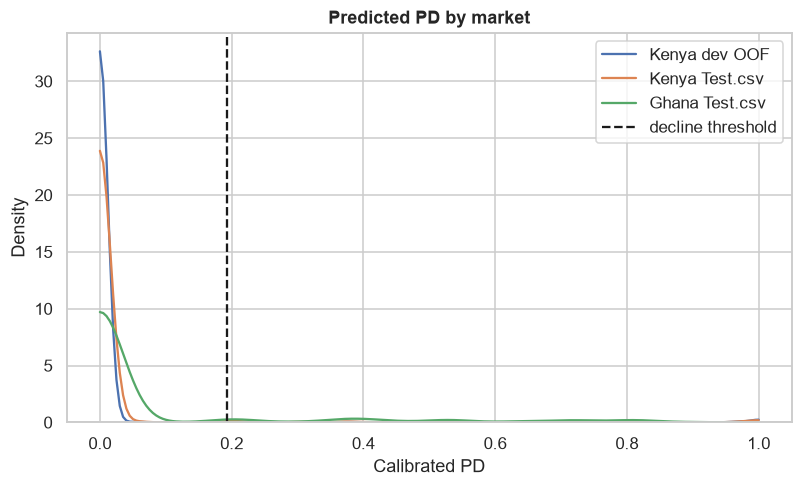

,odds multiplier (Ghana risk vs Kenya),expected default rate,decline rate at fixed threshold
0,0.5,0.0462,0.0984
1,1.0,0.0638,0.1257
2,1.5,0.0745,0.1268
3,2.0,0.0819,0.1268
4,3.0,0.0917,0.1268


Scenario table = sensitivity analysis, not a forecast.


In [6]:
sc_k = cal_f.predict(get_score(pipe_f, K_te[FINAL_FEATS])); sc_g = cal_f.predict(get_score(pipe_f, G[FINAL_FEATS]))
dist = pd.DataFrame({'Kenya dev OOF': [oofp.mean(), np.median(oofp), (oofp >= thr_f).mean()], 'Kenya Test.csv': [sc_k.mean(), np.median(sc_k), (sc_k >= thr_f).mean()],
                     'Ghana Test.csv': [sc_g.mean(), np.median(sc_g), (sc_g >= thr_f).mean()]}, index=['mean PD', 'median PD', 'decline rate at chosen threshold']).T
display(dist.round(4)); dist.to_csv(DIRS['results'] / 'transfer_score_distribution.csv')
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for p_, nm in [(oofp, 'Kenya dev OOF'), (sc_k, 'Kenya Test.csv'), (sc_g, 'Ghana Test.csv')]:
    sns.kdeplot(p_, ax=ax, label=nm, clip=(0, np.quantile(np.r_[oofp, sc_g], .995)), common_norm=False)
ax.axvline(thr_f, color='k', ls='--', label='decline threshold'); ax.set_xlabel('Calibrated PD'); ax.set_title('Predicted PD by market'); ax.legend()
savefig(fig, DIRS, 'plots_tr', 'transfer_score_distributions')
scen = []
for mult in (0.5, 1.0, 1.5, 2.0, 3.0):
    pg = expit(logit(np.clip(sc_g, 1e-6, 1 - 1e-6)) + np.log(mult))
    scen.append({'odds multiplier (Ghana risk vs Kenya)': mult, 'expected default rate': pg.mean(), 'decline rate at fixed threshold': (pg >= thr_f).mean()})
display(pd.DataFrame(scen).round(4)); pd.DataFrame(scen).to_csv(DIRS['results'] / 'transfer_scenarios.csv', index=False)
print('Scenario table = sensitivity analysis, not a forecast.')

**Evidence the lender should require before trusting Ghana scores** (adapt to your outputs):
1. A **labelled pilot**: a small capped-limit Ghanaian cohort, scored blind and followed to maturity, to measure calibration and PR-AUC *in Ghana*.
2. Covariate-shift diagnostics (domain AUC, PSI) within a stated tolerance, re-checked monthly.
3. Ghanaian lenders and loan types must exist in training; unseen levels fall into the "infrequent" bucket (no product knowledge).
4. Ghanaian customers have no Kenyan repayment history, so history features default to "no prior loans": a structural difference, not noise.
5. Local macro indicators (Ghana's 2022–23 inflation is several times Kenya's) and the Findex access picture (Section 3.3).
6. Staged rollout: conservative limits, human review for borderline scores, and a kill-switch.

## 2. Fairness and responsible-AI audit (Part D)
**Scope.** The data has no gender, age or region, so **no claim about those attributes is made**. Groups (as instructed):
`country_id`, `loan_type`, `lender_id`, borrower tenure (`New_versus_Repeat`) and loan-size band. Metrics on the untouched
temporal test set at the chosen threshold. Groups with fewer than 10 defaults are flagged as unreliable. Criteria:
**demographic parity** (decline-rate gap), **equal opportunity** (recall gap), **equalised odds** (max of recall and FPR gaps).
"Selection" here means **being declined**.


=== loan_type ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,Type_1,8938.0,71.0,0.0066,0.7042,0.0010,0.2958,0.8475,0.7692,0.8097,0.0035,True,0.1332,0.6489
1,Type_10,267.0,8.0,0.5206,0.5000,0.5212,0.5000,0.0288,0.0544,0.0336,0.1645,False,0.0150,0.0194
2,Type_11,1.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0070,False,0.0000,0.0001
3,Type_15,2.0,2.0,1.0000,1.0000,0.0000,0.0000,1.0000,1.0000,NaN,0.2500,False,0.0038,0.0001
4,Type_16,12.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0015,False,0.0000,0.0009
5,Type_17,23.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0001,False,0.0000,0.0017
6,Type_19,2.0,0.0,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,NaN,0.9493,False,0.0000,0.0001
7,Type_2,41.0,22.0,0.9268,1.0000,0.8421,0.0000,0.5789,0.7333,0.6819,0.4008,True,0.0413,0.0030
8,Type_20,13.0,7.0,0.4615,0.8571,0.0000,0.1429,1.0000,0.9231,1.0000,0.3292,False,0.0131,0.0009
9,Type_22,1.0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0001,False,0.0000,0.0001



=== lender_grp ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,251804,2241.0,189.0,0.1361,0.6878,0.0853,0.3122,0.4262,0.5263,0.5478,0.0594,True,0.3546,0.1627
1,267277,240.0,58.0,0.4542,0.9655,0.2912,0.0345,0.5138,0.6707,0.7820,0.2202,True,0.1088,0.0174
2,267278,11294.0,286.0,0.0335,0.6748,0.0168,0.3252,0.5106,0.5813,0.6227,0.0149,True,0.5366,0.8199



=== tenure ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,New Loan,175.0,34.0,0.2514,0.8529,0.1064,0.1471,0.6591,0.7436,0.7694,0.1333,True,0.0638,0.0127
1,Repeat Loan,13600.0,499.0,0.0550,0.7014,0.0304,0.2986,0.4679,0.5613,0.6000,0.0243,True,0.9362,0.9873



=== loan_size_band ===


,group,n,defaults,selection_rate (decline),recall (TPR),FPR,FNR,precision,F1,PR-AUC,mean PD,reliable (>=10 defaults),share of all defaults,share of loans
0,Q1 smallest,2632.0,30.0,0.0163,0.7333,0.0081,0.2667,0.5116,0.6027,0.7508,0.0091,True,0.0563,0.1911
1,Q2,3789.0,155.0,0.0293,0.6129,0.0044,0.3871,0.8559,0.7143,0.8007,0.0123,True,0.2908,0.2751
2,Q3,3661.0,99.0,0.0224,0.6768,0.0042,0.3232,0.8171,0.7403,0.6815,0.0118,True,0.1857,0.2658
3,Q4 largest,3693.0,249.0,0.1506,0.7831,0.1048,0.2169,0.3507,0.4845,0.6204,0.0651,True,0.4672,0.2681


,attribute,demographic parity diff,equal opportunity diff (TPR),equalised odds diff,min/max decline-rate ratio
0,loan_type,0.9934,0.4723,0.9990,0.0066
1,lender_grp,0.4207,0.2907,0.2907,0.0737
2,tenure,0.1964,0.1515,0.1515,0.2188
3,loan_size_band,0.1342,0.1702,0.1702,0.1085


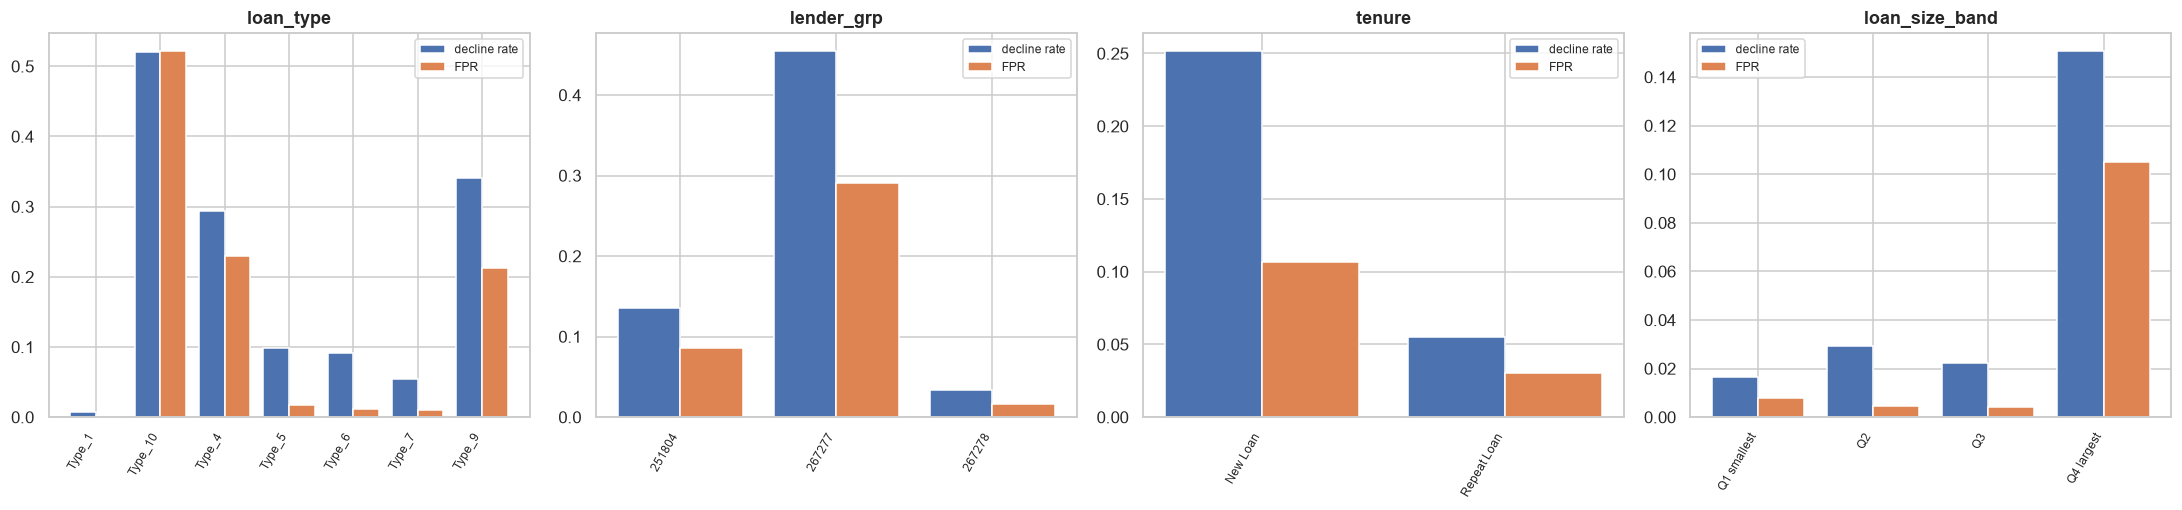

,market,n,mean PD,decline rate
0,Kenya,15069,0.0160,0.0247
1,Ghana,3525,0.0638,0.1257


Country: Ghana is unlabelled, so only score and decline-rate gaps can be reported (no TPR/FPR). A higher Ghana decline rate is NOT evidence of higher risk or of unfairness until Ghana labels exist.


In [7]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, false_negative_rate, demographic_parity_difference, equalized_odds_difference
size_edges = dev['Total_Amount'].quantile([.25, .5, .75]).values
top_lenders = dev['lender_id'].value_counts().head(8).index
FT = test.copy(); FT['pd'] = p_te; FT['decline'] = (FT['pd'] >= thr_f).astype(int)
FT['loan_size_band'] = size_band(FT['Total_Amount'], size_edges).values
FT['lender_grp'] = np.where(FT.lender_id.isin(top_lenders), FT.lender_id, 'other lenders')
GROUPS = {'loan_type': 'loan_type', 'lender_grp': 'lender_grp', 'tenure': 'New_versus_Repeat', 'loan_size_band': 'loan_size_band'}

def fairness_frame(FTd, col):
    y, yp, g = FTd['target'].values, FTd['decline'].values, FTd[col].values
    mf = MetricFrame(metrics={'n': lambda a, b: len(a), 'defaults': lambda a, b: int(a.sum()), 'selection_rate (decline)': selection_rate,
                              'recall (TPR)': true_positive_rate, 'FPR': false_positive_rate, 'FNR': false_negative_rate,
                              'precision': lambda a, b: precision_score(a, b, zero_division=0), 'F1': lambda a, b: f1_score(a, b, zero_division=0)},
                     y_true=y, y_pred=yp, sensitive_features=g)
    t = mf.by_group.copy()
    t['PR-AUC'] = [average_precision_score(y[g == k], FTd['pd'].values[g == k]) if 0 < y[g == k].sum() < (g == k).sum() else np.nan for k in t.index]
    t['mean PD'] = [FTd['pd'].values[g == k].mean() for k in t.index]
    t['reliable (>=10 defaults)'] = t['defaults'] >= 10
    t['share of all defaults'] = t['defaults'] / max(t['defaults'].sum(), 1); t['share of loans'] = t['n'] / t['n'].sum()
    t = t.reset_index(); return t.rename(columns={t.columns[0]: 'group'})

fair_all = []
for nm, col in GROUPS.items():
    t = fairness_frame(FT, col); t['attribute'] = nm; fair_all.append(t); print(f'\n=== {nm} ==='); display(t.drop(columns='attribute').round(4))
fair = pd.concat(fair_all, ignore_index=True); fair.to_csv(DIRS['results'] / 'fairness_results.csv', index=False)
gaps = []
for nm, col in GROUPS.items():
    d = FT[FT[col].map(FT.groupby(col)['target'].sum() >= 10)]
    if d[col].nunique() < 2: gaps.append({'attribute': nm, 'note': 'too few groups with >=10 defaults'}); continue
    ff = fairness_frame(d, col)
    gaps.append({'attribute': nm, 'demographic parity diff': demographic_parity_difference(d.target, d.decline, sensitive_features=d[col]),
                 'equal opportunity diff (TPR)': ff['recall (TPR)'].max() - ff['recall (TPR)'].min(),
                 'equalised odds diff': equalized_odds_difference(d.target, d.decline, sensitive_features=d[col]),
                 'min/max decline-rate ratio': ff['selection_rate (decline)'].min() / max(ff['selection_rate (decline)'].max(), 1e-9)})
gap_tbl = pd.DataFrame(gaps); display(gap_tbl.round(4)); gap_tbl.to_csv(DIRS['results'] / 'fairness_gaps.csv', index=False)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
for a, nm in zip(ax, GROUPS):
    d = fair[(fair.attribute == nm) & (fair.n >= 100)]; x = np.arange(len(d))
    a.bar(x - .2, d['selection_rate (decline)'], .4, label='decline rate'); a.bar(x + .2, d['FPR'], .4, label='FPR')
    a.set_xticks(x); a.set_xticklabels(d.group, rotation=60, ha='right', fontsize=8); a.set_title(nm); a.legend(fontsize=8)
plt.tight_layout(); savefig(fig, DIRS, 'plots_fair', 'fairness_selection_fpr')
cty = pd.DataFrame({'market': ['Kenya', 'Ghana'], 'n': [len(K_te), len(G)], 'mean PD': [sc_k.mean(), sc_g.mean()], 'decline rate': [(sc_k >= thr_f).mean(), (sc_g >= thr_f).mean()]})
display(cty.round(4)); cty.to_csv(DIRS['results'] / 'fairness_country.csv', index=False)
print('Country: Ghana is unlabelled, so only score and decline-rate gaps can be reported (no TPR/FPR). A higher Ghana decline rate is '
      'NOT evidence of higher risk or of unfairness until Ghana labels exist.')

In [8]:
# Who absorbs the risk? Risk concentration by product and lender (test)
for nm in ['loan_type', 'lender_grp']:
    t = fair[fair.attribute == nm][['group', 'n', 'defaults', 'share of loans', 'share of all defaults']].copy()
    t['default rate %'] = 100 * t.defaults / t.n; t['concentration (default share / loan share)'] = t['share of all defaults'] / t['share of loans']
    print(f'\nRisk concentration by {nm}'); display(t[t.n >= 30].sort_values('concentration (default share / loan share)', ascending=False).round(3))

# Proxy analysis: can the remaining features reconstruct the group even when the group column is removed?
size_cols = ['log_amount', 'amount_vs_prior_mean', 'log_prior_mean_amount', 'log_last_amount', 'lender_funded_share', 'lender_repay_share', 'Lender_portion_Funded', 'fee_rate', 'daily_fee_rate']
PROXY_EXCL = {'tenure: New Loan': (dev.New_versus_Repeat == 'New Loan', ['New_versus_Repeat']),
              'tenure: New Loan (also without history)': (dev.New_versus_Repeat == 'New Loan', ['New_versus_Repeat'] + ds.groups['history'] + ['amount_vs_prior_mean']),
              'smallest loan quartile': (size_band(dev.Total_Amount, size_edges) == 'Q1 smallest', size_cols),
              'most common loan type': (dev.loan_type == dev.loan_type.value_counts().index[0], ['loan_type'])}
prox = []
for nm, (ytar, excl) in PROXY_EXCL.items():
    ytar = ytar.astype(int).values
    if ytar.sum() < 10 or ytar.sum() > len(ytar) - 10:
        prox.append({'group': nm, 'n in group': int(ytar.sum()), 'note': 'group too small for a proxy test'}); continue
    fs = [c for c in FINAL_FEATS if c not in excl]
    pp = ImbPipeline([('prep', make_preprocessor(fs)), ('clf', lgb.LGBMClassifier(n_estimators=F(150, 40), learning_rate=0.05, num_leaves=15, random_state=SEED, n_jobs=-1, verbose=-1))])
    s_ = cross_val_predict(pp, dev[fs], ytar, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
    prox.append({'group': nm, 'n in group': int(ytar.sum()), 'AUC predicting group from remaining features': roc_auc_score(ytar, s_),
                 'AUC predicting group from model PD alone': roc_auc_score(ytar, oofp)})
prox = pd.DataFrame(prox); display(prox.round(3)); prox.to_csv(DIRS['results'] / 'proxy_analysis.csv', index=False)
print('AUC well above 0.5 means group information survives removing the column: dropping a column is not the same as being blind to the group.')


Risk concentration by loan_type


,group,n,defaults,share of loans,share of all defaults,default rate %,concentration (default share / loan share)
7,Type_2,41.0,22.0,0.003,0.041,53.659,13.868
15,Type_9,205.0,36.0,0.015,0.068,17.561,4.539
11,Type_4,848.0,88.0,0.062,0.165,10.377,2.682
14,Type_7,2790.0,235.0,0.203,0.441,8.423,2.177
12,Type_5,429.0,36.0,0.031,0.068,8.392,2.169
13,Type_6,185.0,15.0,0.013,0.028,8.108,2.095
1,Type_10,267.0,8.0,0.019,0.015,2.996,0.774
0,Type_1,8938.0,71.0,0.649,0.133,0.794,0.205



Risk concentration by lender_grp


,group,n,defaults,share of loans,share of all defaults,default rate %,concentration (default share / loan share)
17,267277,240.0,58.0,0.017,0.109,24.167,6.246
16,251804,2241.0,189.0,0.163,0.355,8.434,2.180
18,267278,11294.0,286.0,0.820,0.537,2.532,0.654


,group,n in group,AUC predicting group from remaining features,AUC predicting group from model PD alone
0,tenure: New Loan,388,0.977,0.854
1,tenure: New Loan (also without history),388,0.795,0.854
2,smallest loan quartile,13109,0.621,0.494
3,most common loan type,50455,1.000,0.058


AUC well above 0.5 means group information survives removing the column: dropping a column is not the same as being blind to the group.


In [9]:
# Does the imbalance strategy change who gets flagged? (LightGBM, dev OOF, fixed alert budget TOP_Q)
grp = dev['New_versus_Repeat'].values; rows = []
for s, o in A['s2_lgbm_oof'].items():
    thr_ = topq_threshold(o, CFG['TOP_Q'])
    for g in np.unique(grp):
        m = grp == g; yh = (o[m] >= thr_).astype(int); yy = y_dev.values[m]
        rows.append({'strategy': s, 'tenure': g, 'flag rate': yh.mean(), 'recall': yh[yy == 1].mean() if yy.sum() else np.nan, 'FPR': yh[yy == 0].mean()})
imbf = pd.DataFrame(rows); display(imbf.pivot(index='strategy', columns='tenure', values=['flag rate', 'recall', 'FPR']).round(3))
imbf.to_csv(DIRS['results'] / 'fairness_imbalance_strategy.csv', index=False)

flag rate               recall                  FPR            
tenure    New Loan Repeat Loan New Loan Repeat Loan New Loan Repeat Loan
strategy                                                                
adasyn       0.776       0.095      1.0       0.995    0.714       0.085
bsmote       0.763       0.095      1.0       0.997    0.697       0.085
cw           0.552       0.097      1.0       0.995    0.428       0.086
none         0.536       0.097      1.0       0.997    0.408       0.086
ros          0.559       0.097      1.0       0.997    0.438       0.086
rus          0.528       0.097      1.0       0.997    0.398       0.086
smote        0.616       0.096      1.0       0.997    0.510       0.086

### 2.1 Mitigation: tenure-specific thresholds (equal opportunity)
Thresholds per tenure group chosen on **dev OOF** so each group's recall is at least the overall recall, then evaluated once
on test. Group-specific thresholds are **explicit disparate treatment** and may be unacceptable to the regulator: this is a
measured trade-off for the committee, not a recommendation. Alternatives to discuss in the report: a single threshold with
smaller first-loan limits (thin-file ladder), or removing `New_versus_Repeat` and measuring how much proxy information remains.

In [10]:
dev_t, test_t = dev['New_versus_Repeat'].values, FT['New_versus_Repeat'].values
base_rec = ((oofp >= thr_f) & (y_dev.values == 1)).sum() / y_dev.sum(); thr_g = {}
for g in np.unique(dev_t):
    m = dev_t == g; p_g, y_g = oofp[m], y_dev.values[m]
    ok = [t for t in np.unique(np.quantile(p_g, np.linspace(0.5, 0.9995, 300))) if ((p_g >= t) & (y_g == 1)).sum() / max(y_g.sum(), 1) >= base_rec]
    thr_g[g] = max(ok) if ok else thr_f
FT['decline_mit'] = [int(p >= thr_g.get(g, thr_f)) for p, g in zip(FT['pd'], test_t)]
summ = lambda col: FT.groupby('New_versus_Repeat').apply(lambda d: pd.Series({'decline rate': d[col].mean(), 'recall': d.loc[d.target == 1, col].mean(), 'FPR': d.loc[d.target == 0, col].mean(), 'n': len(d), 'defaults': int(d.target.sum())}))
before, after = summ('decline'), summ('decline_mit')
print('Group thresholds (fitted on dev OOF):', {k: round(float(v), 4) for k, v in thr_g.items()})
display(pd.concat({'single threshold': before, 'tenure-specific thresholds': after}, axis=1).round(4))
c0, c1 = expected_cost(y_te, FT['decline'].values, fn_te, fp_te), expected_cost(y_te, FT['decline_mit'].values, fn_te, fp_te)
print(f'Expected cost on test: single {c0*FX:,.0f} {CUR} -> mitigated {c1*FX:,.0f} {CUR} ({100*(c1-c0)/max(c0,1e-9):+.1f}%); '
      f'overall decline rate {FT.decline.mean():.3%} -> {FT.decline_mit.mean():.3%}')
pd.concat({'single': before, 'mitigated': after}, axis=1).to_csv(DIRS['results'] / 'fairness_mitigation.csv')

Group thresholds (fitted on dev OOF): {'New Loan': 0.1827, 'Repeat Loan': 0.0548}


single threshold                                    \
                      decline rate  recall     FPR        n defaults   
New_versus_Repeat                                                      
New Loan                    0.2514  0.8529  0.1064    175.0     34.0   
Repeat Loan                 0.0550  0.7014  0.0304  13600.0    499.0   

                  tenure-specific thresholds                                    
                                decline rate  recall     FPR        n defaults  
New_versus_Repeat                                                               
New Loan                              0.2514  0.8529  0.1064    175.0     34.0  
Repeat Loan                           0.0659  0.7455  0.0400  13600.0    499.0

Expected cost on test: single 10,843,902 KES -> mitigated 11,119,191 KES (+2.5%); overall decline rate 5.750% -> 6.824%


## 3. Model card, regulatory mapping, Findex and borrower explainer
### 3.1 Model Card (Mitchell et al., 2019)
Generated from this run's numbers and saved to `outputs/reports/model_card.md`. Edit the narrative fields to reflect the team's decisions.

In [11]:
T, row_, ci_ = A['TEST']['final'], A['row_final'], A['ci']
f4 = lambda v: f'{v:.4f}'
fl = fair[fair.attribute == 'tenure'][['group', 'n', 'defaults', 'selection_rate (decline)', 'recall (TPR)', 'FPR']].round(3).to_string(index=False)
model_card = f"""# Model Card: NkwaPay default-risk scorer (Task 2)

## Model details
- Type: {FINAL_MODEL} ({FINAL_EXP}), imbalance strategy `{row_['strategy']}`, calibrator `{A['final']['method']}`; seed {SEED}.
- Inputs: {len(FINAL_FEATS)} features from loan terms, calendar, time-safe borrower history{', macro indicators' if CFG['USE_MACRO_FEATURES'] else ''} (macro indicators are joined for monitoring but are not model inputs). No demographic attributes are available or used.
- Output: calibrated probability of default (PD); decline if PD >= {thr_f:.4f}; approve with reduced limit and manual review if PD >= {CFG['REVIEW_FRACTION']*thr_f:.4f}.
- Selection rule: simplest model within one standard error of the best grouped-CV PR-AUC. Library versions: reports/environment_04.json.

## Intended use
- Support (not replace) credit officers approving, limiting and pricing small mobile-money loans. Human review for borderline cases and appeals.
- **Out of scope:** use in Ghana without a local labelled pilot; employment, insurance or any non-credit decision; sole basis of a decline.

## Factors
- Evaluated across loan type, lender, tenure (new vs repeat), loan-size band, and country (Ghana unlabelled: score shift only).

## Metrics (temporal test set, n={len(y_te):,}, defaults={int(y_te.sum())}, prevalence {y_te.mean():.4f})
- PR-AUC {f4(T['pr_auc'])} (95% CI {tuple(round(x, 4) for x in ci_['pr_auc'])}; no-skill {y_te.mean():.4f}); ROC-AUC {f4(T['roc_auc'])}; Brier {f4(T['brier'])}
- At threshold: precision {f4(T['precision'])}, recall {f4(T['recall'])}, F1 {f4(T['f1'])} (95% CI {tuple(round(x, 4) for x in ci_['f1'])}), FPR {f4(T['fpr'])}, decline rate {T['flag_rate']:.3%}
- Paired PR-AUC difference vs tuned logistic regression: {ci_['dpr_auc_vs_lr'][0]:+.4f} (95% CI {ci_['dpr_auc_vs_lr'][1]:+.4f}, {ci_['dpr_auc_vs_lr'][2]:+.4f})
- Dev grouped-CV PR-AUC {f4(row_['pr_auc'])} (fold SD {f4(row_['ap_fold_sd'])})

## Training and evaluation data
- Kenyan loan records (African Credit Scoring Challenge, Zindi): {len(lab):,} loans, default rate {lab.target.mean():.3%}. Dev = loans before {ds.test_start.date()} (resolved before it); test = later loans.
- Amounts in {CFG['CURRENCY']}. Known limits: single market; rare defaults; label grace period undocumented.

## Quantitative analyses (tenure)
```
{fl}
```
Full results: results/fairness_results.csv, fairness_gaps.csv, proxy_analysis.csv, fairness_mitigation.csv, transfer_*.csv.

## Ethical considerations
- Errors fall on people: false negatives push borrowers toward unaffordable debt; false positives deny credit to people who would repay.
- Tenure and loan size are proxies for thin files and low income (see the fairness audit and the mitigation trade-off).
- No gender or region fields exist, so equity on those axes is **unassessed**; Findex Ghana is used for context only.

## Caveats and recommendations
- Do not deploy in Ghana before a labelled pilot. Kenya vs Ghana domain AUC = {DOMAIN_AUC:.3f}. Monitor drift (PSI) and calibration monthly.
- Cost assumptions (recovery {CFG['RECOVERY_RATE']:.0%}, collection {CFG['COLLECTION_COST_RATE']:.0%}) are placeholders unless justified in the report.
"""
(DIRS['reports'] / 'model_card.md').write_text(model_card, encoding='utf-8'); display(Markdown(model_card))

# Model Card: NkwaPay default-risk scorer (Task 2)

## Model details
- Type: lgbm (S3_lgbm_tuned), imbalance strategy `none`, calibrator `isotonic`; seed 42.
- Inputs: 26 features from loan terms, calendar, time-safe borrower history (macro indicators are joined for monitoring but are not model inputs). No demographic attributes are available or used.
- Output: calibrated probability of default (PD); decline if PD >= 0.1923; approve with reduced limit and manual review if PD >= 0.0962.
- Selection rule: simplest model within one standard error of the best grouped-CV PR-AUC. Library versions: reports/environment_04.json.

## Intended use
- Support (not replace) credit officers approving, limiting and pricing small mobile-money loans. Human review for borderline cases and appeals.
- **Out of scope:** use in Ghana without a local labelled pilot; employment, insurance or any non-credit decision; sole basis of a decline.

## Factors
- Evaluated across loan type, lender, tenure (new vs repeat), loan-size band, and country (Ghana unlabelled: score shift only).

## Metrics (temporal test set, n=13,775, defaults=533, prevalence 0.0387)
- PR-AUC 0.6109 (95% CI (0.5547, 0.6663); no-skill 0.0387); ROC-AUC 0.9560; Brier 0.0223
- At threshold: precision 0.4785, recall 0.7111, F1 0.5721 (95% CI (0.524, 0.6217)), FPR 0.0312, decline rate 5.750%
- Paired PR-AUC difference vs tuned logistic regression: +0.3325 (95% CI +0.2699, +0.3915)
- Dev grouped-CV PR-AUC 0.9716 (fold SD 0.0054)

## Training and evaluation data
- Kenyan loan records (African Credit Scoring Challenge, Zindi): 68,654 loans, default rate 1.832%. Dev = loans before 2022-11-02 (resolved before it); test = later loans.
- Amounts in KES. Known limits: single market; rare defaults; label grace period undocumented.

## Quantitative analyses (tenure)
```
      group       n  defaults  selection_rate (decline)  recall (TPR)   FPR
   New Loan   175.0      34.0                     0.251         0.853 0.106
Repeat Loan 13600.0     499.0                     0.055         0.701 0.030
```
Full results: results/fairness_results.csv, fairness_gaps.csv, proxy_analysis.csv, fairness_mitigation.csv, transfer_*.csv.

## Ethical considerations
- Errors fall on people: false negatives push borrowers toward unaffordable debt; false positives deny credit to people who would repay.
- Tenure and loan size are proxies for thin files and low income (see the fairness audit and the mitigation trade-off).
- No gender or region fields exist, so equity on those axes is **unassessed**; Findex Ghana is used for context only.

## Caveats and recommendations
- Do not deploy in Ghana before a labelled pilot. Kenya vs Ghana domain AUC = 1.000. Monitor drift (PSI) and calibration monthly.
- Cost assumptions (recovery 20%, collection 8%) are placeholders unless justified in the report.


### 3.2 Regulatory mapping (draft for legal review)
Maps design choices to the *themes* of the Bank of Ghana Directive for Digital Credit Services Providers, the Data Protection
Act 2012 (Act 843) and the Credit Reporting Act 2007 (Act 726). **Not legal advice**: before submission, check each row against
the official text and cite clause numbers in the audit document.

| Requirement theme | Instrument | Design response in this project | Status |
|---|---|---|---|
| Transparency and disclosure of terms and decisions | BoG Directive | Plain-language reason codes (3.4); full price (fee, daily rate) in features | Partial: no disclosure UI |
| Fair treatment, no discrimination, no predatory lending | BoG Directive | Disaggregated metrics, proxy analysis, mitigation trade-off (Section 2) | Partial: no gender/region data; Ghana unvalidated |
| Responsible lending, avoid over-indebtedness | BoG Directive | Cost-based threshold, approval constraint, limit regression capped at the requested amount | **Cannot satisfy now:** no income, expense or total-debt data to test affordability |
| Lawful processing, consent, purpose limitation, minimisation | Act 843 | Only loan-level fields used; no sensitive attributes | **Cannot verify:** consent records and Ghana data-sharing basis are not in the dataset |
| Cross-border transfer of data and models (Kenyan data, Ghanaian applicants) | Act 843 | Documented in the model card | **Cannot satisfy now:** transfer obligations need legal confirmation |
| Rights of data subjects: access, correction, objection to automated decisions | Act 843 | Reasons returned with each decision; borderline cases routed to manual review | Partial: appeal/correction process must be operationalised |
| Credit reporting: accurate data, bureau reporting, disputes | Act 726 | Out of scope of the model | **Not implemented** |
| Model governance, audit trail, regulator access | BoG Directive | Versioned bundle, config, seeds, model card, saved experiments | Met for this repo; production monitoring pending |
| Local validation | BoG Directive / good practice | Transfer diagnostics only | **Cannot satisfy now:** no Ghana labels |

### 3.3 Debt and access in Ghana: Global Findex 2021 microdata (Part D.4)
**Question:** who in Ghana cannot access credit, and does a scorer trained on existing Kenyan borrowers close or widen that gap?

**Data.** `data/micro_gha.csv`: Global Findex 2021 microdata for Ghana (World Bank Microdata Library, catalog 4646), 1,000
adults aged 15+, with survey weights (`wgt`). All shares below are **weighted** to the adult population. 95 % intervals use the
Kish effective sample size, so groups of ~100 respondents carry ±8–10 point uncertainty. Findex has **no link to individual
loan records**: it describes the population NkwaPay would lend to, not our applicants.

**Codes used** (Findex 2021 codebook; verified here against the published national account rate of 68.2 %):
`female` 1 = woman, 2 = man · `educ` 1 = primary or less, 2 = secondary, 3 = tertiary · `inc_q` 1 = poorest 20 % … 5 = richest 20 % ·
`emp_in` 1 = in workforce, 2 = out of workforce · `urbanicity_f2f` 1 = rural, 2 = urban · `account`, `account_fin`, `account_mob`,
`borrowed`, `saved` are 0/1 · `fin22a` borrowed from a bank or similar financial institution, `fin22b` borrowed from family or
friends (1 = yes, 2 = no, 3 = don't know, 4 = refused).

In [12]:
fdf = load_findex(CFG)
FINDEX_READY = fdf is not None and {'wgt', 'account', 'female'} <= set(fdf.columns)
if FINDEX_READY:
    m = fdf.copy()
    m['No account'] = 1 - m['account']
    m['Mobile money account'] = m['account_mob']
    m['Financial-institution account'] = m['account_fin']
    m['Borrowed any money'] = m['borrowed']
    m['Borrowed from a formal institution'] = (m['fin22a'] == 1).astype(float)
    m['Borrowed from family or friends'] = (m['fin22b'] == 1).astype(float)
    m['Saved any money'] = m['saved']
    OUTCOMES = ['No account', 'Mobile money account', 'Financial-institution account', 'Borrowed any money',
                'Borrowed from a formal institution', 'Borrowed from family or friends', 'Saved any money']
    m['gender'] = m['female'].map({1: 'women', 2: 'men'})
    m['age group'] = pd.cut(m['age'], [14, 24, 39, 59, 120], labels=['15-24', '25-39', '40-59', '60+']).astype(str).replace('nan', np.nan)
    m['education'] = m['educ'].map({1: 'primary or less', 2: 'secondary', 3: 'tertiary'})
    m['income'] = m['inc_q'].map({1: 'poorest 40%', 2: 'poorest 40%', 3: 'richest 60%', 4: 'richest 60%', 5: 'richest 60%'})
    m['income quintile'] = m['inc_q'].map({1: 'Q1 poorest', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5 richest'})
    m['work'] = m['emp_in'].map({1: 'in workforce', 2: 'out of workforce'})
    m['location'] = m['urbanicity_f2f'].map({1: 'rural', 2: 'urban'})
    DIMS = ['gender', 'age group', 'education', 'income', 'income quintile', 'work', 'location']

    def wshare(d, col):
        w, x = d['wgt'].values, d[col].values.astype(float)
        p = np.average(x, weights=w); n_eff = w.sum() ** 2 / (w ** 2).sum()
        return 100 * p, 100 * 1.96 * np.sqrt(max(p * (1 - p), 1e-12) / n_eff), n_eff

    rows = [{'dimension': 'all adults', 'group': 'all adults', 'respondents': len(m), **{o: wshare(m, o)[0] for o in OUTCOMES}}]
    for dim in DIMS:
        for g, d in m.dropna(subset=[dim]).groupby(dim):
            rows.append({'dimension': dim, 'group': g, 'respondents': len(d), **{o: wshare(d, o)[0] for o in OUTCOMES}})
    fx_tab = pd.DataFrame(rows).set_index(['dimension', 'group'])
    print('Ghana 2021, weighted % of adults (15+):'); display(fx_tab.round(1)); fx_tab.to_csv(DIRS['results'] / 'findex_ghana_2021_by_group.csv')
    moe = pd.DataFrame({o: [wshare(m, o)[1]] for o in OUTCOMES}, index=['95% margin of error, all adults (pp)'])
    display(moe.round(1))
else:
    print('Findex microdata not found: save it as data/micro_gha.csv (or set CFG["FINDEX_FILE"]).')

Ghana 2021, weighted % of adults (15+):


respondents  No account  \
dimension       group                                       
all adults      all adults               1000        31.8   
gender          men                       535        25.8   
                women                     465        37.4   
age group       15-24                     291        34.8   
                25-39                     488        25.9   
                40-59                     169        33.3   
                60+                        48        38.2   
education       primary or less           295        48.4   
                secondary                 638        20.5   
                tertiary                   64         1.7   
income          poorest 40%               309        45.3   
                richest 60%               691        22.8   
income quintile Q1 poorest                162        51.9   
                Q2                        147        38.8   
                Q3                        196        29.5   
                Q4                        211        26.4   
                Q5 richest                284        12.6   
work            in workforce              810        26.8   
                out of workforce          190        49.9   
location        rural                     360        43.5   
                urban                     640        23.9   

                                  Mobile money account  \
dimension       group                                    
all adults      all adults                        59.7   
gender          men                               64.6   
                women                             55.0   
age group       15-24                             61.6   
                25-39                             68.0   
                40-59                             54.5   
                60+                               38.7   
education       primary or less                   42.9   
                secondary                         71.1   
                tertiary                          90.7   
income          poorest 40%                       46.4   
                richest 60%                       68.5   
income quintile Q1 poorest                        41.5   
                Q2                                51.1   
                Q3                                59.1   
                Q4                                65.2   
                Q5 richest                        81.2   
work            in workforce                      63.6   
                out of workforce                  45.3   
location        rural                             47.9   
                urban                             67.6   

                                  Financial-institution account  \
dimension       group                                             
all adults      all adults                                 39.2   
gender          men                                        47.3   
                women                                      31.5   
age group       15-24                                      28.5   
                25-39                                      46.9   
                40-59                                      40.5   
                60+                                        41.2   
education       primary or less                            23.9   
                secondary                                  47.2   
                tertiary                                   95.2   
income          poorest 40%                                24.8   
                richest 60%                                48.8   
income quintile Q1 poorest                                 21.1   
                Q2                                         28.3   
                Q3                                         35.7   
                Q4                                         47.2   
                Q5 richest                                 63.5   
work            in wor

,No account,Mobile money account,Financial-institution account,Borrowed any money,Borrowed from a formal institution,Borrowed from family or friends,Saved any money
"95% margin of error, all adults (pp)",3.5,3.7,3.7,3.8,2.0,3.7,3.5


Gaps in percentage points (group minus comparison group):


,dimension,group,vs,No account gap (pp),Mobile money account gap (pp),Borrowed from a formal institution gap (pp),Borrowed from family or friends gap (pp)
0,gender,women,men,11.6,-9.6,-3.4,-4.2
1,income,poorest 40%,richest 60%,22.5,-22.2,-3.9,3.2
2,location,rural,urban,19.6,-19.8,-1.1,-4.2
3,age group,15-24,25-39,8.9,-6.4,-2.8,-2.5
4,education,primary or less,secondary,27.9,-28.2,-2.7,-1.1
5,work,out of workforce,in workforce,23.1,-18.3,-6.3,-7.0


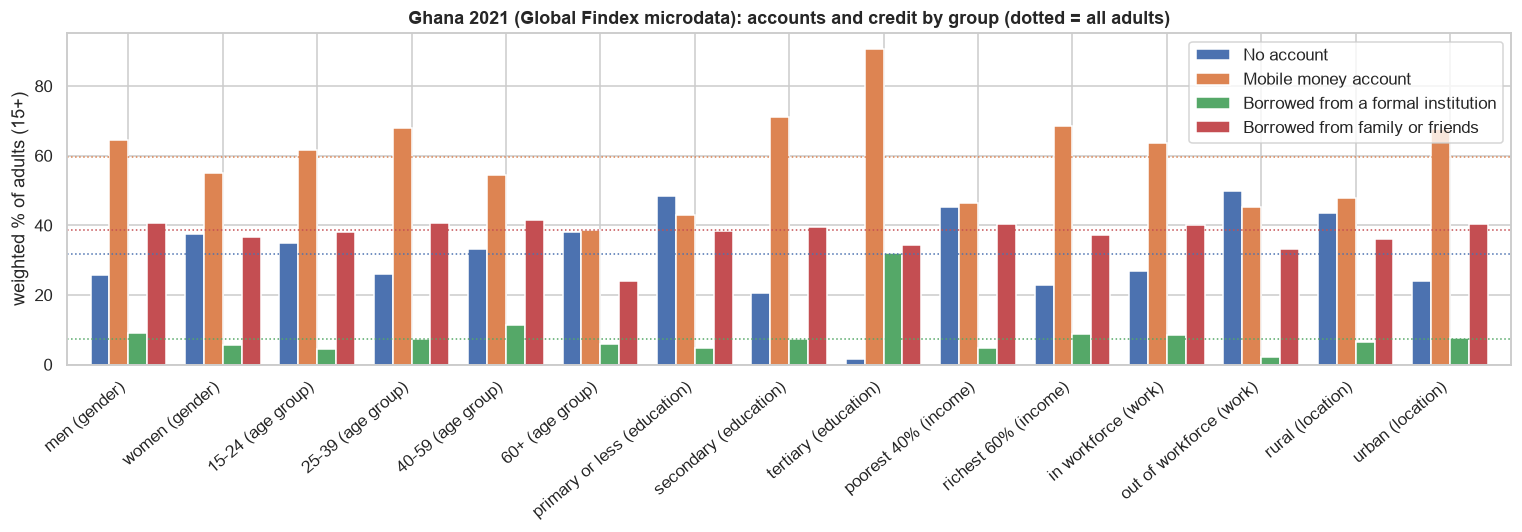

How the scorer treats thin-file applicants:


,decline rate,share with no prior loan in history
Kenya test: new borrowers,0.2514,1.0000
Kenya test: repeat borrowers,0.0550,0.0705
Ghana Test.csv applicants,0.1257,1.0000
Kenya Test.csv applicants,0.0247,0.1045


Ghanaian adults 2021: 31.8% have no account; 52.2% borrowed in the past year, but only 7.2% from a formal institution vs 38.6% from family or friends.


In [13]:
if FINDEX_READY:
    PAIRS = [('gender', 'women', 'men'), ('income', 'poorest 40%', 'richest 60%'), ('location', 'rural', 'urban'),
             ('age group', '15-24', '25-39'), ('education', 'primary or less', 'secondary'), ('work', 'out of workforce', 'in workforce')]
    GAP_O = ['No account', 'Mobile money account', 'Borrowed from a formal institution', 'Borrowed from family or friends']
    gap_f = pd.DataFrame([{'dimension': dim, 'group': a, 'vs': b, **{f'{o} gap (pp)': fx_tab.loc[(dim, a), o] - fx_tab.loc[(dim, b), o] for o in GAP_O}}
                          for dim, a, b in PAIRS if (dim, a) in fx_tab.index and (dim, b) in fx_tab.index])
    print('Gaps in percentage points (group minus comparison group):'); display(gap_f.round(1)); gap_f.to_csv(DIRS['results'] / 'findex_ghana_2021_gaps.csv', index=False)

    plot_o = ['No account', 'Mobile money account', 'Borrowed from a formal institution', 'Borrowed from family or friends']
    sub = fx_tab.drop(index=['all adults', 'income quintile'], level=0)[plot_o]
    sub.index = [f'{g} ({d})' for d, g in sub.index]
    fig, ax = plt.subplots(figsize=(14, 5)); sub.plot.bar(ax=ax, width=.8)
    for o, c in zip(plot_o, plt.rcParams['axes.prop_cycle'].by_key()['color']):
        ax.axhline(fx_tab.loc[('all adults', 'all adults'), o], color=c, ls=':', lw=1)
    ax.set_ylabel('weighted % of adults (15+)'); ax.set_title('Ghana 2021 (Global Findex microdata): accounts and credit by group (dotted = all adults)')
    plt.setp(ax.get_xticklabels(), rotation=40, ha='right'); plt.tight_layout(); savefig(fig, DIRS, 'plots_fair', 'findex_ghana_2021_groups')

    # Link to the model: how does the scorer treat thin-file applicants, the group Findex places outside formal credit?
    tn = fair[fair.attribute == 'tenure'].set_index('group')
    link = pd.DataFrame({
        'decline rate': [tn.loc['New Loan', 'selection_rate (decline)'], tn.loc['Repeat Loan', 'selection_rate (decline)'], (sc_g >= thr_f).mean(), (sc_k >= thr_f).mean()],
        'share with no prior loan in history': [(test.loc[test.New_versus_Repeat == 'New Loan', 'n_prior_loans'] == 0).mean(),
                                                (test.loc[test.New_versus_Repeat == 'Repeat Loan', 'n_prior_loans'] == 0).mean(),
                                                (G.n_prior_loans == 0).mean(), (K_te.n_prior_loans == 0).mean()]},
        index=['Kenya test: new borrowers', 'Kenya test: repeat borrowers', 'Ghana Test.csv applicants', 'Kenya Test.csv applicants'])
    print('How the scorer treats thin-file applicants:'); display(link.round(4)); link.to_csv(DIRS['results'] / 'findex_model_link.csv')
    a_ = fx_tab.loc[('all adults', 'all adults')]
    print(f"Ghanaian adults 2021: {a_['No account']:.1f}% have no account; {a_['Borrowed any money']:.1f}% borrowed in the past year, "
          f"but only {a_['Borrowed from a formal institution']:.1f}% from a formal institution vs {a_['Borrowed from family or friends']:.1f}% from family or friends.")

**How to write this up (use the numbers above).**
1. **Who is excluded.** Read `No account` and the gap table: identify which groups (gender, income, location, age, education,
   work) are furthest from accounts and from formal credit. Compare formal borrowing with borrowing from family and friends:
   that difference is the unmet demand a digital lender targets. Check the respondent counts and margins before calling a gap real.
2. **What the model does to them.** The scorer leans on borrower history. Every Ghanaian applicant is a thin-file applicant to
   a Kenyan model (no prior loans in the history store), and in Kenya first-time borrowers are declined far more often than
   repeat borrowers (table above); the proxy analysis in Section 2 shows tenure is recoverable from other features.
3. **Closes or widens?** Left as is, the tool would tend to **widen** the gap: the people Findex places outside formal credit are
   the people without a repayment record, so they score worse for lack of data rather than for evidence of risk.
4. **Mitigations to propose:** a thin-file ladder (small first limit, automatic increases after on-time repayment) instead of a
   decline; separate calibration for first loans from a Ghana pilot; consented alternative data (mobile-money cash flow, given
   the high mobile-money account rate); monitoring decline rates by tenure and, once collected with consent, by gender and region.

### 3.4 Borrower-facing explanation of a declined application

In [14]:
reasons = ReasonBuilder(REASONS)
idx_hi = int(np.argmax(p_te))
cs_hi = contributions(pipe_f, test.iloc[[idx_hi]], FINAL_FEATS).iloc[0]
rs = reasons(cs_hi)
explainer = f"""# Why your loan application was not approved

Thank you for applying. We are sorry that we could not approve this loan today.

**What we looked at.** We used the details of your application (loan type, amount, repayment period, and your loan record with us, if any). We did not use your gender, religion, ethnicity or where you live.

**The main reasons**
""" + '\n'.join(f'{i+1}. {t}' for i, (_, _, t) in enumerate(rs)) + """

**What this means.** This decision comes from a computer model that estimates how likely a loan like this is to be repaid on time. It is not a judgement of you as a person, and the model can be wrong.

**What you can do**
- Ask for a person to review the decision. You have the right to ask, and to ask us to correct wrong information about you.
- Apply again for a smaller amount or a longer period; repaying earlier loans on time improves future decisions.
- Borrow only what you can repay comfortably. Missed repayments can lead to extra costs.

Contact: [NkwaPay support number and email to be inserted]
"""
(DIRS['reports'] / 'borrower_explainer.md').write_text(explainer, encoding='utf-8'); display(Markdown(explainer))

# Why your loan application was not approved

Thank you for applying. We are sorry that we could not approve this loan today.

**What we looked at.** We used the details of your application (loan type, amount, repayment period, and your loan record with us, if any). We did not use your gender, religion, ethnicity or where you live.

**The main reasons**
1. The total cost of this loan is high relative to the amount borrowed.
2. The daily cost of this loan is high because the term is short.
3. The share of the repayment owed to the lender.

**What this means.** This decision comes from a computer model that estimates how likely a loan like this is to be repaid on time. It is not a judgement of you as a person, and the model can be wrong.

**What you can do**
- Ask for a person to review the decision. You have the right to ask, and to ask us to correct wrong information about you.
- Apply again for a smaller amount or a longer period; repaying earlier loans on time improves future decisions.
- Borrow only what you can repay comfortably. Missed repayments can lead to extra costs.

Contact: [NkwaPay support number and email to be inserted]


## 4. Scoring service (Part E)
`src/prosit2/scoring_service.py` loads one bundle (pipeline, calibrator, threshold, history store, macro table, limit model,
reason texts) and exposes `Scorer.score(application) → {probability_of_default, decision, approved_limit, top_reasons, latency_ms}`.
It uses the same `prosit2.features` code as training (no train/serve skew). The decision policy (approve / approve with reduced
limit and manual review / decline) is a **proposal for the credit committee**.

In [15]:
from prosit2.scoring_service import Scorer, REQUIRED_FIELDS
BUNDLE_PATH = DIRS['ckpt_best'] / 'final_bundle.joblib'
bundle = dict(pipeline=pipe_f, calibrator=cal_f, threshold=float(thr_f), review_fraction=CFG['REVIEW_FRACTION'],
              features=FINAL_FEATS, model=FINAL_MODEL, version=f'{FINAL_EXP}@{pd.Timestamp.now():%Y%m%d}', grace_days=CFG['GRACE_DAYS'],
              history=lab[['customer_id', 'disbursement_date', 'due_date', 'Total_Amount', 'target']].copy(), econ=ds.econ, macro_lag=CFG['MACRO_LAG_YEARS'],
              limit_pipeline=joblib.load(R['model_path']), limit_resid_sd=R['resid_sd'], reason_fn=reasons, currency=CFG['CURRENCY'],
              config=CFG, seed=SEED, env=ENV, test_metrics={k: {m: v for m, v in d.items() if isinstance(v, (int, float, str))} for k, d in A['TEST'].items()})
joblib.dump(bundle, BUNDLE_PATH); print('Saved bundle ->', BUNDLE_PATH, f'({BUNDLE_PATH.stat().st_size/1e6:.1f} MB)')

scorer = Scorer(BUNDLE_PATH)
to_app = lambda r: {k: (r[k].isoformat() if k == 'disbursement_date' else (r[k].item() if hasattr(r[k], 'item') else r[k])) for k in REQUIRED_FIELDS}
app = to_app(test.iloc[idx_hi])
print('Example request (what the application must send):'); print(json.dumps(app, indent=2, default=str))
out = scorer.score(app); print('\nResponse:'); print(json.dumps(out, indent=2, default=str))
assert abs(out['probability_of_default'] - p_te[idx_hi]) < 1e-6, 'service and notebook scores disagree (train/serve skew!)'
print('\nParity check passed: service PD equals notebook PD for the same applicant.')
lat = [scorer.score(to_app(test.iloc[i % len(test)]))['latency_ms'] for i in range(F(200, 30))]
print(f'Latency over {len(lat)} single-application calls (1 process, in-memory): mean {np.mean(lat):.1f} ms, p95 {np.percentile(lat, 95):.1f} ms, max {np.max(lat):.1f} ms')
try:
    scorer.score({k: v for k, v in app.items() if k != 'duration'})
except ValueError as e:
    print('Input validation works:', e)

Saved bundle -> <repo>\outputs\checkpoints\best_models\final_bundle.joblib (4.5 MB)


Example request (what the application must send):
{
  "customer_id": 268637,
  "country_id": "Kenya",
  "loan_type": "Type_1",
  "lender_id": "267278",
  "duration": 7,
  "disbursement_date": "2022-11-02T00:00:00",
  "Total_Amount": 1739.0,
  "Total_Amount_to_Repay": 2804.0,
  "Amount_Funded_By_Lender": 521.7,
  "Lender_portion_Funded": 0.3,
  "Lender_portion_to_be_repaid": 841.0,
  "New_versus_Repeat": "Repeat Loan"
}

Response:
{
  "probability_of_default": 1.0,
  "decision": "decline",
  "approved_limit": 0.0,
  "threshold": 0.19230769230769232,
  "top_reasons": [
    {
      "feature": "fee_rate",
      "contribution": 9.636016637507248,
      "text": "The total cost of this loan is high relative to the amount borrowed."
    },
    {
      "feature": "daily_fee_rate",
      "contribution": 2.5071317088892595,
      "text": "The daily cost of this loan is high because the term is short."
    },
    {
      "feature": "lender_repay_share",
      "contribution": 0.4827122057638812,
  

Latency over 200 single-application calls (1 process, in-memory): mean 56.0 ms, p95 68.0 ms, max 75.0 ms
Input validation works: missing required fields: ['duration']


## 5. Consolidated summary and reproducibility record

In [16]:
TEST = A['TEST']
summary_json = dict(created=str(pd.Timestamp.now()), seed=SEED, config=CFG, environment=ENV, n_train_rows=int(len(lab)), n_dev=int(len(dev)), n_test=int(len(test)),
    default_rate=float(lab.target.mean()), test_start=str(ds.test_start.date()), final_model=FINAL_MODEL, final_experiment=FINAL_EXP,
    imbalance_strategy=A['BEST_STRAT'].get(FINAL_MODEL), calibrator=A['final']['method'], threshold=float(thr_f), analytic_p_star=float(A['p_star']),
    best_hyperparameters=A['BEST_PARAMS'], test_metrics={k: {m: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for m, v in d.items()} for k, d in TEST.items()},
    bootstrap_ci=A['ci'], regression_best=R['BEST_REG'], regression_test=R['reg_test'].loc[R['BEST_REG']].to_dict(),
    domain_auc=float(DOMAIN_AUC), ghana_decline_rate=float((sc_g >= thr_f).mean()), failed_experiments=A['failed'])
(DIRS['reports'] / 'experiment_summary.json').write_text(json.dumps(summary_json, indent=2, default=str))
rt = R['reg_test']
report = f"""FINAL MODEL REPORT ({pd.Timestamp.now():%Y-%m-%d %H:%M})
=====================================================
Selected model: {FINAL_MODEL} ({FINAL_EXP}); rule: simplest model within 1 SE of the best grouped-CV PR-AUC.
Imbalance strategy: {A['row_final']['strategy']} | calibrator: {A['final']['method']} | decline threshold: {thr_f:.4f} (analytic p* {A['p_star']:.4f})
Data: {len(lab):,} loans, default rate {lab.target.mean():.3%}; dev {len(dev):,} / test {len(test):,} (test = loans from {ds.test_start.date()}).

DEV (grouped CV): PR-AUC {A['row_final']['pr_auc']:.4f}, fold mean {A['row_final']['ap_fold_mean']:.4f} +- {A['row_final']['ap_fold_sd']:.4f}
TEST (one shot): PR-AUC {TEST['final']['pr_auc']:.4f} (95% CI {tuple(round(x, 4) for x in A['ci']['pr_auc'])}), ROC-AUC {TEST['final']['roc_auc']:.4f},
  precision {TEST['final']['precision']:.4f}, recall {TEST['final']['recall']:.4f}, F1 {TEST['final']['f1']:.4f} (95% CI {tuple(round(x, 4) for x in A['ci']['f1'])})
  expected cost {TEST['final']['expected_cost']*FX:,.0f} {CUR} vs approve-all {TEST['majority_approve_all']['expected_cost']*FX:,.0f} {CUR}
Paired difference vs tuned logistic regression: dPR-AUC {A['ci']['dpr_auc_vs_lr'][0]:+.4f} CI ({A['ci']['dpr_auc_vs_lr'][1]:+.4f}, {A['ci']['dpr_auc_vs_lr'][2]:+.4f})
Task 1 ({R['BEST_REG']}): RMSE(log) {rt.loc[R['BEST_REG'], 'rmse_log']:.4f} vs mean baseline {rt.loc['mean', 'rmse_log']:.4f}; MAE(orig) {rt.loc[R['BEST_REG'], 'mae_orig']*FX:,.1f} {CUR}
Transfer: Kenya vs Ghana domain AUC {DOMAIN_AUC:.3f}; Ghana decline rate at the Kenyan threshold {(sc_g >= thr_f).mean():.2%} (Kenya Test.csv {(sc_k >= thr_f).mean():.2%})

LIMITATIONS
- Single-country labels; Ghana performance is unmeasured (shift diagnostics only).
- Cost-matrix recovery and collection rates are assumptions; amounts are in {CFG['CURRENCY']} unless FX_TO_GHS is set.
- Few test defaults (n={int(y_te.sum())}): wide intervals; subgroup metrics unreliable below 10 defaults.
- No gender/region/age data: fairness on those axes is unassessed. Group-specific thresholds may be legally problematic.
- History features cannot exist for new Ghana customers; SMOTE interpolates one-hot columns; selection optimism reduced, not eliminated.
- Lender_portion_to_be_repaid / funding columns need data-owner confirmation of decision-time availability (see ablation E5).
"""
(DIRS['reports'] / 'final_model_report.txt').write_text(report, encoding='utf-8'); print(report)

FINAL MODEL REPORT (2026-11-12 15:15)
Selected model: lgbm (S3_lgbm_tuned); rule: simplest model within 1 SE of the best grouped-CV PR-AUC.
Imbalance strategy: none | calibrator: isotonic | decline threshold: 0.1923 (analytic p* 0.0252)
Data: 68,654 loans, default rate 1.832%; dev 52,331 / test 13,775 (test = loans from 2022-11-02).

DEV (grouped CV): PR-AUC 0.9716, fold mean 0.9714 +- 0.0054
TEST (one shot): PR-AUC 0.6109 (95% CI (0.5547, 0.6663)), ROC-AUC 0.9560,
  precision 0.4785, recall 0.7111, F1 0.5721 (95% CI (0.524, 0.6217))
  expected cost 10,843,902 KES vs approve-all 82,531,793 KES
Paired difference vs tuned logistic regression: dPR-AUC +0.3325 CI (+0.2699, +0.3915)
Task 1 (lgbm): RMSE(log) 0.7213 vs mean baseline 1.3509; MAE(orig) 15,491.1 KES
Transfer: Kenya vs Ghana domain AUC 1.000; Ghana decline rate at the Kenyan threshold 12.57% (Kenya Test.csv 2.47%)

LIMITATIONS
- Single-country labels; Ghana performance is unmeasured (shift diagnostics only).
- Cost-matrix recover